In [1]:
#Shishir Khanal
#Sept 10, 2026
#Lunar lander using Deep Deterministic Policy Gradient (DDPG) algorithm using Tensorflow

In [2]:
import gym
import pygame
import numpy as np
import tensorflow as tf
import tensorflow.keras as keras
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
import tensorflow_probability as tfp
import matplotlib.pyplot as plt

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
2026-09-11 11:31:29.627570: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
#Replay buffer: Fixed size, overwrites early memories with new ones
class ReplayBuffer():
    def __init__(self, max_size, input_shape, n_actions):
        self.mem_size = max_size
        self.mem_cntr = 0
        self.state_memory = np.zeros((self.mem_size, *input_shape)) #'*' means unpack list of elements
        self.new_state_memory = np.zeros((self.mem_size, *input_shape))
        self.action_memory = np.zeros((self.mem_size, n_actions)) #For lunar lander 4 element
        self.reward_memory = np.zeros(self.mem_size)
        self.terminal_memory = np.zeros(self.mem_size, dtype=bool) #mask for setting critique values for new states to 0

    def store_transition(self, state, action, reward, state_, done):
        index = self.mem_cntr % self.mem_size
        self.state_memory[index] = state
        self.action_memory[index] = action
        self.reward_memory[index] = reward
        self.new_state_memory[index] = state_
        self.terminal_memory[index] = done
        self.mem_cntr += 1

    def sample_buffer(self, batch_size):
        max_mem = min(self.mem_cntr, self.mem_size)
        batch = np.random.choice(max_mem, batch_size)
        states = self.state_memory[batch] 
        actions = self.action_memory[batch] 
        rewards = self.reward_memory[batch]
        states_ = self.new_state_memory[batch]
        dones = self.terminal_memory[batch]

        return states, actions, rewards, states_, dones 

In [4]:
class ActorNetwork(keras.Model):
    def __init__(self, n_actions, fc1_dims=1024, fc2_dims=512):
        super(ActorNetwork, self).__init__()
        self.fc1 = Dense(fc1_dims, activation='relu', name='fc1')
        self.fc2 = Dense(fc2_dims, activation='relu', name='fc2')
        self.mu = Dense(n_actions, activation='tanh', name='mu')
    
    def call(self, state):
        x = self.fc1(state)
        x = self.fc2(x)
        mu = self.mu(x)
        return mu

In [5]:
class CriticNetwork(keras.Model):
    def __init__(self, fc1_dims=1024, fc2_dims=512):
        super(CriticNetwork, self).__init__()
        self.fc1 = Dense(fc1_dims, activation='relu', name='fc1')
        self.fc2 = Dense(fc2_dims, activation='relu', name='fc2')
        self.q = Dense(1, activation=None, name='q')
    
    def call(self, inputs):    #inputs ~ (state, action)
        state, action = inputs
        x = self.fc1(tf.concat([state, action], axis=1))
        x = self.fc2(x)
        q = self.q(x)
        return q

In [6]:
class Agent:
    def __init__(self, alpha=0.001, beta=0.002, gamma=0.99, n_actions=4, fc1_dims=400, fc2_dims=300, 
                 max_size=1_000_000, batch_size=64, noise=0.1, tau=0.005, input_dims=[8], env=None, chkpt_dir ='models/'):
        self.gamma = gamma
        self.alpha = alpha
        self.beta = beta
        self.tau = tau
        self.batch_size = batch_size
        self.n_actions = n_actions
        self.noise = noise
        self.max_action = env.action_space.high[0]
        self.min_action = env.action_space.low[0]

        self.chkpt_dir = chkpt_dir
        self.actor = ActorNetwork(n_actions=n_actions, fc1_dims=fc1_dims, fc2_dims=fc2_dims)
        self.critic = CriticNetwork(fc1_dims=fc1_dims, fc2_dims=fc2_dims)

        self.target_actor = ActorNetwork(n_actions=n_actions, fc1_dims=fc1_dims, fc2_dims=fc2_dims)
        self.target_critic = CriticNetwork(fc1_dims=fc1_dims, fc2_dims=fc2_dims)
        
        self.actor.compile(optimizer=Adam(learning_rate=alpha))
        self.critic.compile(optimizer=Adam(learning_rate=alpha))
        self.target_actor.compile(optimizer=Adam(learning_rate=alpha))
        self.target_critic.compile(optimizer=Adam(learning_rate=alpha))

        self.memory = ReplayBuffer(max_size, input_dims, n_actions)
        self.update_network_parameters(tau=1)

    def update_network_parameters(self, tau=None):
        if tau is None:
            tau = self.tau

        weights = []
        targets = self.target_actor.weights
        for i, weight in enumerate(self.actor.weights):
            weights.append(weight * tau + targets[i] * (1 - tau))
        self.target_actor.set_weights(weights)

        weights = []
        targets = self.target_critic.weights
        for i, weight in enumerate(self.critic.weights):
            weights.append(weight * tau + targets[i] * (1 - tau))
        self.target_critic.set_weights(weights)

    def save_models(self):
        self.actor.save_weights(self.chkpt_dir + 'actor.weights.h5')
        self.critic.save_weights(self.chkpt_dir + 'critic.weights.h5')
        self.target_actor.save_weights(self.chkpt_dir + 'target_actor.weights.h5')
        self.target_critic.save_weights(self.chkpt_dir + 'target_critic.weights.h5')
        print('Model saved successfully...')

    def load_models(self):
        dummy_state = tf.zeros((1, 8), dtype=tf.float32)
        dummy_action = tf.zeros((1, 2), dtype=tf.float32)
    
        self.actor(dummy_state, training=False)
        self.critic((dummy_state, dummy_action), training=False)
        self.target_actor(dummy_state, training=False)
        self.target_critic((dummy_state, dummy_action), training=False)
    
        self.actor.load_weights(self.chkpt_dir + 'actor.weights.h5')
        self.critic.load_weights(self.chkpt_dir + 'critic.weights.h5')
        self.target_actor.load_weights(self.chkpt_dir + 'target_actor.weights.h5')
        self.target_critic.load_weights(self.chkpt_dir + 'target_critic.weights.h5')
    
        print('Models loaded successfully...')

    def store_transition(self, state, action, reward, new_state, done):
        self.memory.store_transition(state, action, reward, new_state, done)

    def choose_action(self, observation, evaluate=False):
        state = tf.convert_to_tensor([observation], dtype=tf.float32)
        actions = self.actor(state)
        if not evaluate:
            actions += tf.random.normal(shape=[self.n_actions], mean=0.0, stddev=self.noise)
        actions = tf.clip_by_value(actions, self.min_action, self.max_action)

        return actions[0]

    def learn(self):
        if self.memory.mem_cntr < self.batch_size:
            return

        state, action, reward, new_state, done = self.memory.sample_buffer(self.batch_size)
        
        states = tf.convert_to_tensor(state, dtype=tf.float32)
        states_ = tf.convert_to_tensor(new_state, dtype=tf.float32)
        rewards = tf.convert_to_tensor(reward, dtype=tf.float32)
        actions = tf.convert_to_tensor(action, dtype=tf.float32)

        with tf.GradientTape() as tape:
            new_policy_actions = self.actor(states)
            actor_loss = -self.critic((states, new_policy_actions))
            actor_loss = tf.math.reduce_mean(actor_loss)
            
        params = self.actor.trainable_variables
        grads = tape.gradient(actor_loss, params)
        self.actor.optimizer.apply_gradients(zip(grads, params))

        with tf.GradientTape() as tape:
            target_actions = self.target_actor(states_)
            critic_value_ = tf.squeeze(self.target_critic((states_, target_actions)), 1)
            critic_value = tf.squeeze(self.critic((states, actions)), 1)
            target = rewards + self.gamma * critic_value_ * (1 - done)
            critic_loss = keras.losses.MSE(target, critic_value)
        params = self.critic.trainable_variables
        grads = tape.gradient(critic_loss, params)
        self.critic.optimizer.apply_gradients(zip(grads, params))

        self.update_network_parameters()

In [7]:
def plot_learning_curve(scores, x, figure_file):
    running_avg = np.zeros(len(scores))
    for i in range(len(running_avg)):
        running_avg[i] = np.mean(scores[max(0, i-100):(i+1)])
    plt.plot(x, running_avg)
    plt.title('Running average of previous 100 scores')
    plt.show()
    plt.savefig(figure_file)

In [ ]:
import pygame
import numpy as np

if __name__ == '__main__':
    render_every = 199  # set to 1 to watch every episode (slow)
    env = gym.make('LunarLanderContinuous-v2', render_mode="rgb_array")
    agent = Agent(gamma=0.99, alpha=1e-4, beta=1e-3, n_actions=env.action_space.shape[0], env=env)
    n_games = 1000
    load_checkpoint = False
    best_score = env.reward_range[0]
    if load_checkpoint:
        n_games = 1
        agent.load_models()
    filename = 'LunarLander_alpha_' + str(agent.alpha) + '_beta_' + str(agent.beta) + '_' + str(n_games) + '_games_'
    figure_file = 'plots/' + filename + '.png'
    scores = []

    pygame.init()
    env.reset()  # must reset before the first render() call
    frame = env.render()  # grab one frame to get dimensions
    window = pygame.display.set_mode((frame.shape[1], frame.shape[0]))
    pygame.display.set_caption('LunarLanderContinuous - Agent')
    episode_font = pygame.font.SysFont('Arial', 24)
    clock = pygame.time.Clock()

    for i in range(n_games):
        done = False
        observation, info = env.reset()
        score = 0
        render_this_episode = (i % render_every == 0)
        #agent.noise.reset()

        while not done:
            action = agent.choose_action(observation)
            observation_, reward, truncated, terminated, info = env.step(action)
            done = truncated or terminated
            score += reward
            if not load_checkpoint:
                agent.store_transition(observation, action, reward, observation_, done)
                agent.learn()
            observation = observation_  # current state = new state

            if render_this_episode:
                pygame.event.pump()  # keep OS from thinking window is frozen
                frame = env.render()  # returns an (H, W, 3) rgb array
                surf = pygame.surfarray.make_surface(frame.swapaxes(0, 1))
                window.blit(surf, (0, 0))

                text_surface = episode_font.render(
                    f'Episode {i + 1}/{n_games}', True, (255, 255, 255)
                )
                window.blit(text_surface, (10, 10))

                pygame.display.flip()
                clock.tick(60)

        scores.append(score)
        avg_score = np.mean(scores[-100:])

        if avg_score > best_score:
            if not load_checkpoint:
                agent.save_models()
            best_score = avg_score

        print('episode {} score {:.1f} average score {:.1f}'.format(i, score, avg_score))

    pygame.quit()
    x = [i + 1 for i in range(n_games)]

In [8]:
if __name__ == '__main__':
    #env = gym.make('LunarLanderContinuous-v2', render_mode="human")
    env = gym.make('LunarLanderContinuous-v2')
    agent = Agent(gamma=0.99, alpha=1e-4, beta=1e-3, n_actions=env.action_space.shape[0], env=env)
    n_games = 1000
    load_checkpoint = False
    best_score = env.reward_range[0]
    if load_checkpoint:
        n_games = 1
        agent.load_models()
    filename = 'LunarLander_alpha_' + str(agent.alpha) + '_beta_' + str(agent.beta) +'_' + str(n_games) + '_games_'
    figure_file = 'plots/'+filename + '.png'
    scores = []
    for i in range(n_games):
        done = False
        observation, info = env.reset()
        score = 0
        #agent.noise.reset()
        while not done:
            action = agent.choose_action(observation)
            observation_, reward, truncated, terminated, info = env.step(action)
            done = truncated or terminated
            score += reward
            if not load_checkpoint:
                agent.store_transition(observation, action, reward, observation_, done)
                agent.learn()
            observation = observation_ #current state = new state
        scores.append(score)
        
        avg_score = np.mean(scores[-100:])
        #env.render()
        if avg_score > best_score:
            if not load_checkpoint:
                agent.save_models()
            best_score = avg_score

        print('episode {} score {:.1f} average score {:.1f}'.format(i, score, avg_score))

    x = [i+1 for i in range(n_games)]

2026-09-11 11:31:32.457018: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_COMPAT_NOT_SUPPORTED_ON_DEVICE: forward compatibility was attempted on non supported HW
2026-09-11 11:31:32.457051: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:171] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
2026-09-11 11:31:32.457057: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:176] retrieving CUDA diagnostic information for host: shishir
2026-09-11 11:31:32.457061: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:183] hostname: shishir
2026-09-11 11:31:32.457270: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:190] libcuda reported version is: 580.178.4
2026-09-11 11:31:32.457295: I external/local_xla/xla/stream_executor/cuda/cud

Model saved successfully...
episode 0 score -119.8 average score -119.8
episode 1 score -134.2 average score -127.0
episode 2 score -601.0 average score -285.0
episode 3 score -183.8 average score -259.7
episode 4 score -109.3 average score -229.6
episode 5 score -214.9 average score -227.2
episode 6 score -212.6 average score -225.1
episode 7 score -122.6 average score -212.3
episode 8 score -213.8 average score -212.4
episode 9 score -210.9 average score -212.3
episode 10 score -133.9 average score -205.2
episode 11 score -254.7 average score -209.3
episode 12 score -247.7 average score -212.2
episode 13 score -371.1 average score -223.6
episode 14 score -52.4 average score -212.2
episode 15 score 278.3 average score -181.5
episode 16 score -106.5 average score -177.1
episode 17 score -73.6 average score -171.3
episode 18 score -125.6 average score -168.9
episode 19 score -205.5 average score -170.8
episode 20 score -183.9 average score -171.4
episode 21 score -152.8 average score -1

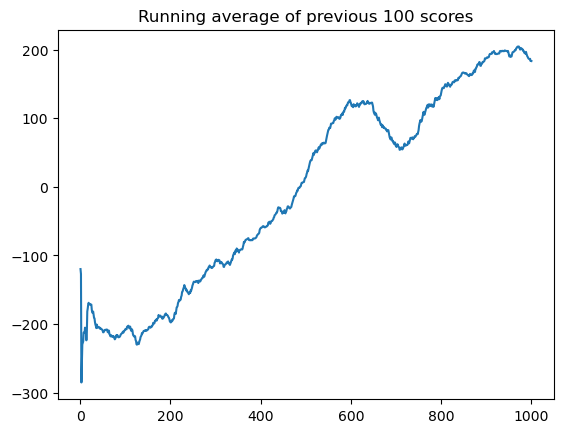

<Figure size 640x480 with 0 Axes>

In [9]:
plot_learning_curve(scores=scores, x=x, figure_file=figure_file)